# Air Quality Index (AQI) Prediction Using Machine Learning and the KDD Process

**Environment:** Google Colab  
**Dataset:** [Air Quality Data in India (Kaggle)](https://www.kaggle.com/datasets/rohanrao/air-quality-data-in-india)  
**Prediction target:** `AQI` (numeric regression)

## Project objective

This project applies the Knowledge Discovery in Databases (KDD) process to historical city-level air-quality data. It explores pollutant measurements, trains regression models to estimate AQI, compares model performance, and examines influential features.

## KDD workflow

1. **Selection:** Load `city_day.csv` and identify available pollutant, city, date, and AQI fields.
2. **Preprocessing:** Standardize column names, parse dates, remove duplicate records, inspect missing values, and exclude rows without a valid target.
3. **Transformation:** Create calendar features, impute missing predictor values within a machine-learning pipeline, and encode city categories.
4. **Data mining:** Compare a median baseline, Linear Regression, and Random Forest regression.
5. **Evaluation and interpretation:** Evaluate predictions on a chronological holdout set using MAE, RMSE, and R², and examine residuals and feature importance.

**Scope:** The Kaggle `city_day.csv` dataset contains pollutant measurements and AQI but does not provide temperature or humidity fields in this daily table. The notebook uses the columns available in the dataset.

**Task definition:** This notebook estimates same-day AQI from same-day pollutant measurements. It is not a future-day forecasting system.

## 1. Library setup

The following cell installs the required Python packages. The next cell imports the libraries used for data processing, visualization, preprocessing, model training, and evaluation.

In [4]:
%pip -q install pandas numpy matplotlib seaborn scikit-learn

In [5]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Data selection and loading

Download the Kaggle dataset and upload `city_day.csv` to Google Colab. The notebook locates the uploaded CSV and loads it for analysis. Uploading the file directly avoids storing Kaggle credentials in the notebook.

In [6]:
# Locate the uploaded CSV. The notebook expects the daily city-level file.
csv_candidates = glob.glob("/content/**/city_day.csv", recursive=True)
if not csv_candidates:
    csv_candidates = glob.glob("/content/*.csv")
if not csv_candidates:
    raise FileNotFoundError("Upload city_day.csv (from the Kaggle dataset) and rerun this cell.")

DATA_PATH = csv_candidates[0]
df_raw = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Shape:", df_raw.shape)
display(df_raw.head())
print("\nActual columns:")
print(df_raw.columns.tolist())

Loaded: /content/city_day.csv
Shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN



Actual columns:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']


### Source data fields

The daily dataset may contain `City`, `Date`, pollutant columns (`PM2.5`, `PM10`, `NO`, `NO2`, `NOx`, `NH3`, `CO`, `SO2`, `O3`, `Benzene`, `Toluene`, and `Xylene`), `AQI`, and `AQI_Bucket`. The notebook checks the actual columns at runtime and uses only fields that are present.

## 3. Preprocessing and data quality

This stage standardizes column names, parses dates, handles duplicate records, reviews missing values, and prepares valid rows for modeling.

In [7]:
df = df_raw.copy()
df.columns = [str(c).strip() for c in df.columns]

required_target = "AQI"
if required_target not in df.columns:
    raise ValueError(f"Target '{required_target}' not found. Available columns: {df.columns.tolist()}")

if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Duplicate rows:", int(df.duplicated().sum()))
print("\nMissing values (top 20):")
display(df.isna().sum().sort_values(ascending=False).head(20).to_frame("missing_count"))
print("\nMissing-value percentage (top 20):")
display((100 * df.isna().mean()).sort_values(ascending=False).head(20).round(2).to_frame("missing_percent"))

df = df.drop_duplicates()
df = df.dropna(subset=["AQI"])
df = df[df["AQI"].apply(lambda x: pd.notna(x) and np.isfinite(float(x)))]
print("Shape after removing duplicates and rows without AQI:", df.shape)

Duplicate rows: 0

Missing values (top 20):


,missing_count
Xylene,18109
PM10,11140
NH3,10328
Toluene,8041
Benzene,5623
AQI,4681
AQI_Bucket,4681
PM2.5,4598
NOx,4185
O3,4022



Missing-value percentage (top 20):


,missing_percent
Xylene,61.32
PM10,37.72
NH3,34.97
Toluene,27.23
Benzene,19.04
AQI,15.85
AQI_Bucket,15.85
PM2.5,15.57
NOx,14.17
O3,13.62


Shape after removing duplicates and rows without AQI: (24850, 16)


## 4. Exploratory data analysis

The following outputs summarize the selected dataset and visualize AQI distributions and other available data patterns. The charts and descriptive statistics are generated from the dataset loaded at runtime.

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
City,24850,26,Delhi,1999,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,24850,NaN,NaN,NaN,2018-07-24 18:51:25.714285568,2015-01-01 00:00:00,2017-08-16 00:00:00,2018-11-05 00:00:00,2019-10-11 00:00:00,2020-07-01 00:00:00,NaN
PM2.5,24172.0,NaN,NaN,NaN,67.476613,0.04,29.0,48.785,80.925,914.94,63.075398
PM10,17764.0,NaN,NaN,NaN,118.454435,0.03,56.7775,96.18,150.1825,917.08,89.487976
NO,24463.0,NaN,NaN,NaN,17.622421,0.03,5.66,9.91,20.03,390.68,22.421138
NO2,24459.0,NaN,NaN,NaN,28.978391,0.01,11.94,22.1,38.24,362.21,24.627054
NOx,22993.0,NaN,NaN,NaN,32.289012,0.0,13.11,23.68,40.17,378.24,30.712855
NH3,18314.0,NaN,NaN,NaN,23.848366,0.01,8.96,16.31,30.36,352.89,25.875981
CO,24405.0,NaN,NaN,NaN,2.345267,0.0,0.59,0.93,1.48,175.81,7.075208
SO2,24245.0,NaN,NaN,NaN,14.362933,0.01,5.73,9.22,15.14,186.08,17.428693


Number of cities: 26


,records
City,
Delhi,1999
Bengaluru,1910
Lucknow,1893
Chennai,1884
Hyderabad,1880
Patna,1459
Gurugram,1453
Ahmedabad,1334
Visakhapatnam,1171


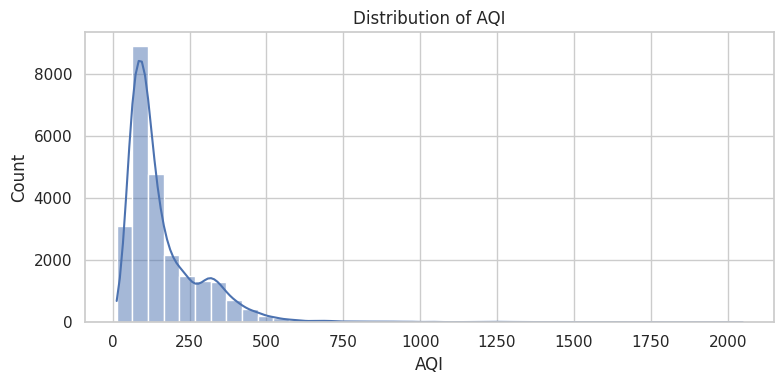

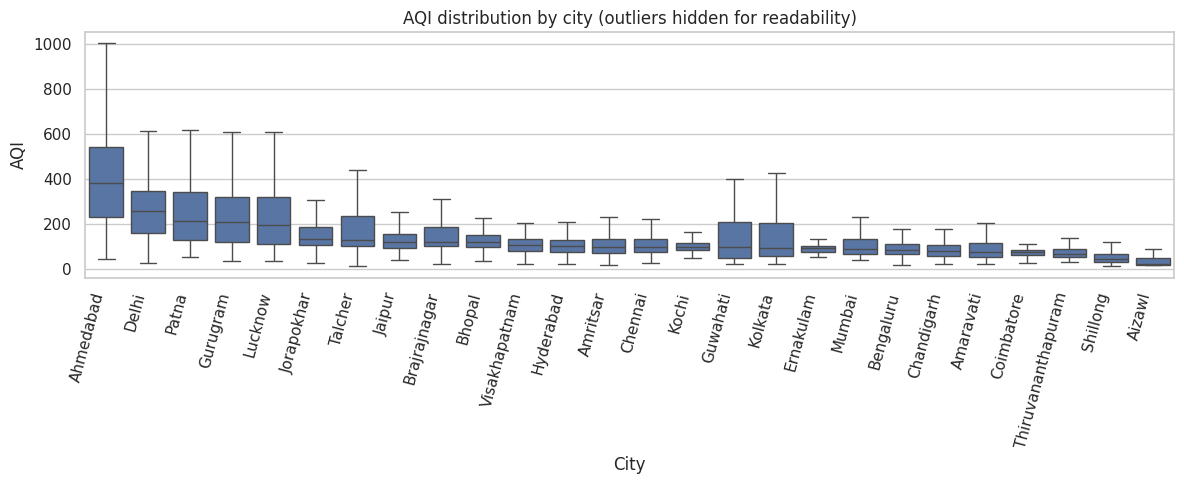

In [8]:
display(df.describe(include="all").T)
if "City" in df.columns:
    print("Number of cities:", df["City"].nunique())
    display(df["City"].value_counts().head(10).to_frame("records"))

plt.figure(figsize=(8, 4))
sns.histplot(df["AQI"], bins=40, kde=True)
plt.title("Distribution of AQI")
plt.xlabel("AQI")
plt.tight_layout()
plt.show()

if "City" in df.columns:
    plt.figure(figsize=(12, 5))
    city_order = df.groupby("City")["AQI"].median().sort_values(ascending=False).index
    sns.boxplot(data=df, x="City", y="AQI", order=city_order, showfliers=False)
    plt.xticks(rotation=75, ha="right")
    plt.title("AQI distribution by city (outliers hidden for readability)")
    plt.tight_layout()
    plt.show()

## 5. Feature transformation

`AQI` is the prediction target. `AQI_Bucket` is excluded because it is derived from AQI and would introduce target leakage. The date is transformed into calendar features rather than passed directly to the estimator. Missing predictor values are imputed inside the machine-learning pipeline, so imputation statistics are learned from the training data only.

This is a same-day AQI estimation task using same-day pollutant readings, not a future-day forecast. Future forecasting would require features available before the prediction date and a forward-shifted AQI target.

In [9]:
pollutant_candidates = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3",
    "Benzene", "Toluene", "Xylene"
]
pollutant_cols = [c for c in pollutant_candidates if c in df.columns]

if not pollutant_cols:
    raise ValueError("No expected pollutant columns found. Inspect df.columns and update pollutant_candidates.")

if "Date" in df.columns:
    df["Year"] = df["Date"].dt.year
    df["Month"] = df["Date"].dt.month
    df["DayOfYear"] = df["Date"].dt.dayofyear
    date_features = ["Year", "Month", "DayOfYear"]
else:
    date_features = []

city_features = ["City"] if "City" in df.columns else []
feature_cols = pollutant_cols + date_features + city_features
target_col = "AQI"

# Keep only rows with a valid date when Date is available, to make chronological splitting reliable.
if "Date" in df.columns:
    df = df.dropna(subset=["Date"]).sort_values("Date").reset_index(drop=True)
else:
    df = df.reset_index(drop=True)

X = df[feature_cols].copy()
y = pd.to_numeric(df[target_col], errors="coerce")
valid = y.notna() & np.isfinite(y)
X, y, df_model = X.loc[valid].copy(), y.loc[valid].copy(), df.loc[valid].copy()

numeric_features = [c for c in feature_cols if c != "City"]
categorical_features = [c for c in feature_cols if c == "City"]

print("Predictor columns:", feature_cols)
print("Target:", target_col)
print("Modeling rows:", len(X))
print("Target missing after filtering:", int(y.isna().sum()))

Predictor columns: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'Year', 'Month', 'DayOfYear', 'City']
Target: AQI
Modeling rows: 24850
Target missing after filtering: 0


## 6. Chronological train/test split

The data is split in time order: the earliest 80% of records are used for training and the latest 20% for testing. This helps evaluate performance on later observations. Because multiple cities share dates, this setup evaluates later dates for the represented cities; it does not measure generalization to unseen cities.

In [10]:
split_idx = int(len(df_model) * 0.80)
if split_idx < 10 or len(df_model) - split_idx < 2:
    raise ValueError("Not enough rows for an 80/20 chronological split.")

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
df_test = df_model.iloc[split_idx:].copy()

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
if "Date" in df_model.columns:
    print("Training date range:", df_model["Date"].iloc[0], "to", df_model["Date"].iloc[split_idx-1])
    print("Testing date range:", df_model["Date"].iloc[split_idx], "to", df_model["Date"].iloc[-1])

Train rows: 19880 | Test rows: 4970
Training date range: 2015-01-01 00:00:00 to 2019-12-06 00:00:00
Testing date range: 2019-12-06 00:00:00 to 2020-07-01 00:00:00


## 7. Model training and comparison

The notebook compares a median baseline, Linear Regression, and Random Forest regression. Preprocessing is fitted on the training data through scikit-learn pipelines to reduce data leakage.

In [11]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

models = {
    "Median baseline": DummyRegressor(strategy="median"),
    "Linear Regression": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", LinearRegression())
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=250, min_samples_leaf=2,
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}

fitted_models = {}
predictions = {}
rows = []

for name, model in models.items():
    if name == "Median baseline":
        model.fit(X_train[numeric_features], y_train)
        pred = model.predict(X_test[numeric_features])
    else:
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
    fitted_models[name] = model
    predictions[name] = pred
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "R2": r2_score(y_test, pred)
    })

results = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
display(results.round(3))

,Model,MAE,RMSE,R2
0,Random Forest,16.561,27.044,0.910
1,Linear Regression,21.984,32.785,0.867
2,Median baseline,60.703,90.008,-0.001


### Evaluation metrics

- **MAE (Mean Absolute Error):** Average absolute prediction error in AQI points; lower values indicate better performance.
- **RMSE (Root Mean Squared Error):** Gives larger errors more weight; lower values indicate better performance.
- **R² (Coefficient of Determination):** Measures performance relative to predicting the test-set mean. Values closer to 1 indicate stronger fit; negative values are possible.

The notebook calculates these metrics from the actual chronological test split when executed.

Lowest-RMSE model on this holdout: Random Forest
MAE: 16.561
RMSE: 27.044
R2: 0.91


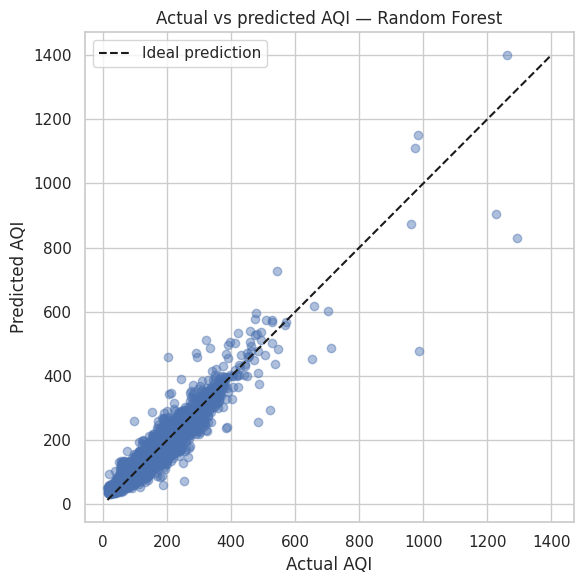

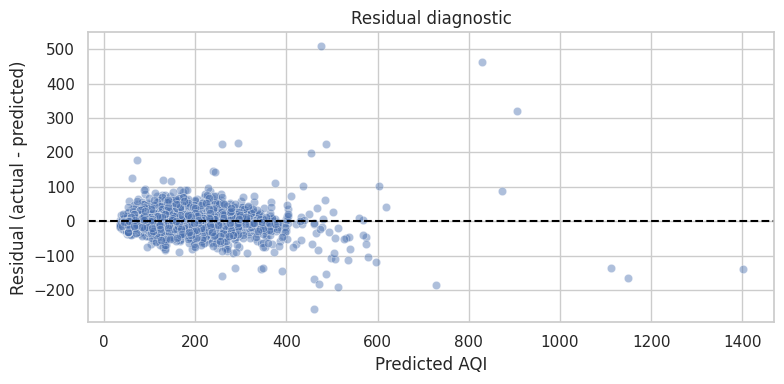

In [12]:
best_name = results.iloc[0]["Model"]
best_pred = predictions[best_name]
print("Lowest-RMSE model on this holdout:", best_name)
print("MAE:", round(mean_absolute_error(y_test, best_pred), 3))
print("RMSE:", round(mean_squared_error(y_test, best_pred) ** 0.5, 3))
print("R2:", round(r2_score(y_test, best_pred), 3))

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, alpha=0.45)
lims = [
    min(float(y_test.min()), float(np.min(best_pred))),
    max(float(y_test.max()), float(np.max(best_pred)))
]
plt.plot(lims, lims, "k--", label="Ideal prediction")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title(f"Actual vs predicted AQI — {best_name}")
plt.legend()
plt.tight_layout()
plt.show()

residuals = y_test.to_numpy() - best_pred
plt.figure(figsize=(8, 4))
sns.scatterplot(x=best_pred, y=residuals, alpha=0.45)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Predicted AQI")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residual diagnostic")
plt.tight_layout()
plt.show()

## 8. Feature importance and interpretation

The notebook calculates permutation importance on the held-out test set for the fitted Random Forest model. This indicates which features most affect model performance in this evaluation. It describes association and model reliance, not proof that a pollutant causes AQI changes.

,Feature,Importance_MAE_increase,Std
0,PM2.5,28.1723,0.1792
1,PM10,16.7741,0.1372
6,CO,10.2873,0.1203
8,O3,3.1354,0.1056
2,NO,0.9360,0.0952
15,City,0.6364,0.0945
4,NOx,0.6038,0.0509
3,NO2,0.2164,0.0273
5,NH3,0.1843,0.0250
7,SO2,0.1645,0.0216


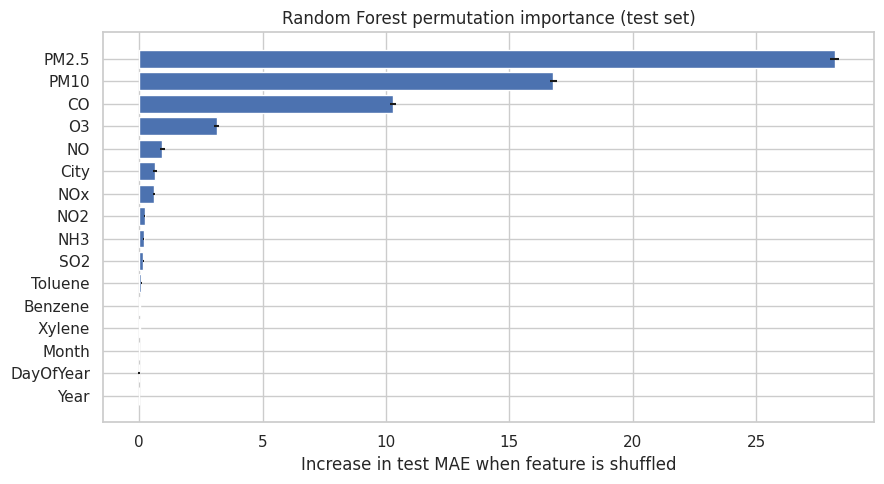

In [13]:
rf = fitted_models["Random Forest"]
perm = permutation_importance(
    rf, X_test, y_test,
    n_repeats=5, random_state=RANDOM_STATE,
    scoring="neg_mean_absolute_error", n_jobs=-1
)
importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_MAE_increase": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values("Importance_MAE_increase", ascending=False)

display(importance.round(4))
plt.figure(figsize=(9, 5))
plot_data = importance.sort_values("Importance_MAE_increase", ascending=True)
plt.barh(plot_data["Feature"], plot_data["Importance_MAE_increase"], xerr=plot_data["Std"])
plt.xlabel("Increase in test MAE when feature is shuffled")
plt.title("Random Forest permutation importance (test set)")
plt.tight_layout()
plt.show()

## 9. Example predictions and export

The notebook displays actual and predicted AQI values for selected held-out observations. It also exports a prediction table from the model with the lowest RMSE on the test set.

In [14]:
prediction_output = pd.DataFrame({
    "Actual_AQI": y_test.to_numpy(),
    "Predicted_AQI": best_pred,
    "Absolute_Error": np.abs(y_test.to_numpy() - best_pred)
}, index=X_test.index)

for col in ["City", "Date"]:
    if col in df_test.columns:
        prediction_output.insert(0, col, df_test[col].values)

display(prediction_output.head(15).round(2))
prediction_output.to_csv("aqi_test_predictions.csv", index=False)
results.to_csv("aqi_model_comparison.csv", index=False)
importance.to_csv("aqi_feature_importance.csv", index=False)
print("Saved: aqi_test_predictions.csv, aqi_model_comparison.csv, aqi_feature_importance.csv")

,Date,City,Actual_AQI,Predicted_AQI,Absolute_Error
19880,2019-12-06,Chennai,107.0,99.56,7.44
19881,2019-12-06,Chandigarh,186.0,163.65,22.35
19882,2019-12-07,Visakhapatnam,92.0,96.08,4.08
19883,2019-12-07,Jorapokhar,234.0,221.38,12.62
19884,2019-12-07,Bengaluru,89.0,89.81,0.81
19885,2019-12-07,Jaipur,189.0,165.41,23.59
19886,2019-12-07,Delhi,382.0,387.84,5.84
19887,2019-12-07,Chandigarh,139.0,137.95,1.05
19888,2019-12-07,Kolkata,163.0,163.29,0.29
19889,2019-12-07,Ahmedabad,276.0,352.03,76.03


Saved: aqi_test_predictions.csv, aqi_model_comparison.csv, aqi_feature_importance.csv


## 10. KDD summary and limitations

This project follows the KDD workflow from source-data selection through preprocessing, feature transformation, model training, evaluation, and interpretation. The notebook outputs the processed row counts, model comparison metrics, example predictions, visualizations, and feature-importance results when executed.

The best-performing model is selected by test-set RMSE. Its MAE, RMSE, and R² are calculated from the chronological holdout data, and the feature-importance plot summarizes the Random Forest model's most influential predictors. These results depend on the dataset version and the completed notebook run.

### Limitations

- AQI is estimated from pollutant measurements recorded on the same day; the notebook does not forecast future-day AQI.
- Missing data, differences between cities, and changes over time may affect model performance.
- The `city_day.csv` table used here does not include temperature or humidity.
- The chronological holdout represents later observations from the cities in the dataset; it does not establish performance in unseen cities.
- The results should not be used for health, regulatory, or other high-stakes decisions without additional validation.

### Future improvements

A future-day forecasting version could create lagged pollutant features, shift the AQI target forward by one or more days, and evaluate the predictions using a chronological split. Additional validation across cities and time periods would help assess generalization.

### Reproducibility

Run all notebook cells from top to bottom in Google Colab. The metrics and plots are generated from the dataset supplied at runtime.

**Dataset source:** [Kaggle — Air Quality Data in India](https://www.kaggle.com/datasets/rohanrao/air-quality-data-in-india).